<a href="https://colab.research.google.com/github/yeondajang/Computer-vision/blob/main/HW2/knn_HW(2023112684%20%EC%9E%A5%EB%8B%A4%EC%97%B0).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from tensorflow.keras.datasets import cifar10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 2243s 13us/step


In [ ]:
import os
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option('display.float_format', '{:.4f}'.format)

In [ ]:
to_vec = lambda x: x.transpose(0, 3, 1, 2).reshape(len(x), -1).astype(np.float32)

X_train_all, y_train_all = to_vec(x_train), y_train.flatten().astype(np.int64)
X_test_all, y_test_all = to_vec(x_test), y_test.flatten().astype(np.int64)
CLASSES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck']

print('학습 데이터  :', X_train_all.shape, y_train_all.shape)
print('테스트 데이터:', X_test_all.shape, y_test_all.shape)

학습 데이터  : (50000, 3072) (50000,)
테스트 데이터: (10000, 3072) (10000,)


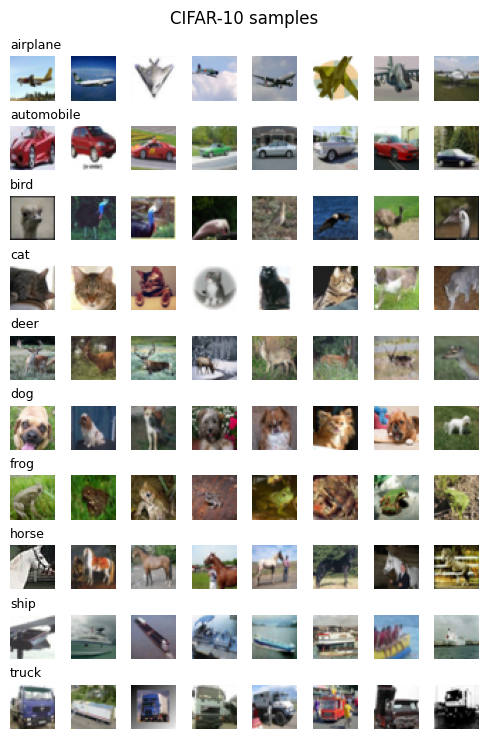

In [ ]:
def to_image(x):
    return x.reshape(3, 32, 32).transpose(1, 2, 0) / 255.0

fig, axes = plt.subplots(10, 8, figsize=(5, 7.5))
for c in range(10):
    idx = rng.choice(np.where(y_train_all == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(to_image(X_train_all[i]))
        ax.axis('off')
    axes[c, 0].set_title(CLASSES[c], fontsize=9, loc='left')
plt.suptitle('CIFAR-10 samples')
plt.tight_layout()
plt.show()

In [ ]:
N_TRAIN_PER_CLASS = 500
N_TEST_PER_CLASS = 100

def stratified_subsample(X, y, n_per_class, rng):
    idx = np.concatenate([rng.choice(np.where(y == c)[0], n_per_class, replace=False)
                          for c in np.unique(y)])
    rng.shuffle(idx)
    return X[idx], y[idx]

X_tr, y_tr = stratified_subsample(X_train_all, y_train_all, N_TRAIN_PER_CLASS, rng)
X_te, y_te = stratified_subsample(X_test_all, y_test_all, N_TEST_PER_CLASS, rng)
X_tr, X_te = X_tr / 255.0, X_te / 255.0

print('학습:', X_tr.shape, ' 클래스별 개수:', np.bincount(y_tr))
print('테스트:', X_te.shape, ' 클래스별 개수:', np.bincount(y_te))

학습: (5000, 3072)  클래스별 개수: [500 500 500 500 500 500 500 500 500 500]
테스트: (1000, 3072)  클래스별 개수: [100 100 100 100 100 100 100 100 100 100]


In [ ]:
class KNN:
    def __init__(self, metric='l2'):
        assert metric in ('l1', 'l2', 'cosine')
        self.metric = metric

    def fit(self, X, y):
        self.X_train = X.astype(np.float32)
        self.y_train = y
        self.n_classes = int(y.max()) + 1
        return self

    def compute_distances(self, X):
        X = X.astype(np.float32)
        Xtr = self.X_train
        if self.metric == 'l2':
            sq = (X ** 2).sum(1)[:, None] + (Xtr ** 2).sum(1)[None, :] - 2 * X @ Xtr.T
            return np.sqrt(np.maximum(sq, 0))
        if self.metric == 'l1':
            D = np.empty((X.shape[0], Xtr.shape[0]), dtype=np.float32)
            for i in range(X.shape[0]):
                D[i] = np.abs(Xtr - X[i]).sum(1)
            return D
        # cosine
        Xn = X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-12)
        Tn = Xtr / (np.linalg.norm(Xtr, axis=1, keepdims=True) + 1e-12)
        return 1.0 - Xn @ Tn.T

    def vote(self, neighbor_labels):
        n, k = neighbor_labels.shape
        rows = np.arange(n)
        counts = np.zeros((n, self.n_classes), dtype=np.int64)
        first_pos = np.full((n, self.n_classes), k, dtype=np.int64)
        for j in range(k - 1, -1, -1):
            counts[rows, neighbor_labels[:, j]] += 1
            first_pos[rows, neighbor_labels[:, j]] = j
        return np.argmax(counts * (k + 1) - first_pos, axis=1)

    def neighbor_order(self, X, max_k):
        D = self.compute_distances(X)
        part = np.argpartition(D, max_k - 1, axis=1)[:, :max_k]
        order = np.take_along_axis(part, np.argsort(np.take_along_axis(D, part, 1), axis=1), 1)
        return order

    def predict(self, X, k=1, order=None):
        if order is None:
            order = self.neighbor_order(X, k)
        return self.vote(self.y_train[order[:, :k]])

In [ ]:
toy_X = np.array([[0, 0], [1, 0], [0, 1], [5, 5], [6, 5], [5, 6]], dtype=np.float32)
toy_y = np.array([0, 0, 0, 1, 1, 1])
toy_q = np.array([[0.5, 0.5], [5.5, 5.2], [2.4, 2.4]], dtype=np.float32)

for m in ['l1', 'l2', 'cosine']:
    knn = KNN(m).fit(toy_X, toy_y)
    print(f'{m:>6} | k=1 →', knn.predict(toy_q, k=1), '| k=3 →', knn.predict(toy_q, k=3))

    l1 | k=1 → [0 1 0] | k=3 → [0 1 0]
    l2 | k=1 → [0 1 0] | k=3 → [0 1 0]
cosine | k=1 → [1 1 1] | k=3 → [1 1 1]


In [ ]:
def evaluate(y_true, y_pred):
    return {
        'accuracy':  accuracy_score(y_true, y_pred),
        'precision': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall':    recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1':        f1_score(y_true, y_pred, average='macro', zero_division=0),
    }

In [ ]:
K_LIST = [1, 3, 5, 7, 9, 11, 15, 20, 30, 50]
METRICS = ['l1', 'l2', 'cosine']
N_FOLDS = 5

fold_idx = np.array_split(rng.permutation(len(X_tr)), N_FOLDS)
records = []
t_all = time.time()
for metric in METRICS:
    t0 = time.time()
    for f in range(N_FOLDS):
        val = fold_idx[f]
        trn = np.concatenate([fold_idx[g] for g in range(N_FOLDS) if g != f])
        knn = KNN(metric).fit(X_tr[trn], y_tr[trn])
        order = knn.neighbor_order(X_tr[val], max(K_LIST))
        for k in K_LIST:
            pred = knn.predict(X_tr[val], k=k, order=order)
            records.append({'metric': metric, 'k': k, 'fold': f + 1, **evaluate(y_tr[val], pred)})
cv = pd.DataFrame(records)
cv.head()

,metric,k,fold,accuracy,precision,recall,f1
0,l1,1,1,0.3330,0.3595,0.3249,0.3218
1,l1,3,1,0.3490,0.3843,0.3401,0.3347
2,l1,5,1,0.3530,0.4036,0.3430,0.3358
3,l1,7,1,0.3490,0.4095,0.3406,0.3320
4,l1,9,1,0.3560,0.4567,0.3468,0.3426


In [ ]:
SCORES = ['accuracy', 'precision', 'recall', 'f1']
summary = cv.groupby(['metric', 'k'])[SCORES].agg(['mean', 'std'])

for s in SCORES:
    pv = summary[(s, 'mean')].unstack('metric')[METRICS]
    pv.columns = ['L1', 'L2', 'Cosine']
    print(f'\n[{s}]')
    display(pv.style.format('{:.4f}').highlight_max(axis=None, props='color:red'))


[accuracy]


,L1,L2,Cosine
k,,,
1,0.2944,0.2720,0.2894
3,0.3066,0.2798,0.2964
5,0.3092,0.2834,0.3028
7,0.3056,0.2834,0.2964
9,0.3086,0.2830,0.2952
11,0.3094,0.2816,0.2938
15,0.3062,0.2798,0.2892
20,0.3052,0.2776,0.2884
30,0.3004,0.2798,0.2850



[precision]


,L1,L2,Cosine
k,,,
1,0.3220,0.3024,0.3129
3,0.3407,0.3208,0.3218
5,0.3626,0.3465,0.3421
7,0.3726,0.3592,0.3515
9,0.3950,0.3710,0.3583
11,0.3932,0.3698,0.3475
15,0.4033,0.3798,0.3639
20,0.4164,0.3855,0.3635
30,0.4207,0.3975,0.3818



[recall]


,L1,L2,Cosine
k,,,
1,0.2938,0.2726,0.2898
3,0.3066,0.2801,0.2965
5,0.3089,0.2836,0.3030
7,0.3052,0.2833,0.2966
9,0.3084,0.2832,0.2954
11,0.3093,0.2815,0.2940
15,0.3063,0.2804,0.2894
20,0.3053,0.2781,0.2887
30,0.3009,0.2802,0.2858



[f1]


,L1,L2,Cosine
k,,,
1,0.2865,0.2598,0.2789
3,0.2969,0.2659,0.2810
5,0.2970,0.2647,0.2849
7,0.2933,0.2622,0.2774
9,0.2965,0.2618,0.2745
11,0.2946,0.2578,0.2699
15,0.2908,0.2518,0.2638
20,0.2888,0.2458,0.2591
30,0.2814,0.2448,0.2540


In [ ]:
labels = {'l1': 'L1 (Manhattan)', 'l2': 'L2 (Euclidean)', 'cosine': 'Cosine'}
best_k_each = summary[('accuracy', 'mean')].groupby('metric').idxmax().map(lambda t: t[1])

In [ ]:
best_metric, best_k = summary[('accuracy', 'mean')].idxmax()
print(f'교차검증 최적 설정: 거리 = {best_metric}, k = {best_k}')

test_rows = []
for m in METRICS:
    k = int(best_k_each[m])
    pred = KNN(m).fit(X_tr, y_tr).predict(X_te, k=k)
    test_rows.append({'metric': labels[m], 'k': k, **evaluate(y_te, pred)})
test_df = pd.DataFrame(test_rows).set_index('metric')
test_df

교차검증 최적 설정: 거리 = l1, k = 11


,k,accuracy,precision,recall,f1
metric,,,,,
L1 (Manhattan),11,0.3040,0.3750,0.3040,0.2876
L2 (Euclidean),5,0.2640,0.3290,0.2640,0.2442
Cosine,5,0.3080,0.3503,0.3080,0.2898


In [ ]:
acc_mean = summary[('accuracy', 'mean')]
names = {'l1': 'L1', 'l2': 'L2', 'cosine': '코사인'}

print('거리 방식별 최적 k (5-fold 평균 정확도)')
for m in METRICS:
    k = best_k_each[m]
    print(f'  - {names[m]}: k={k}, 정확도 {acc_mean[(m, k)]:.4f} '
          f'(k=1: {acc_mean[(m, 1)]:.4f}, k={K_LIST[-1]}: {acc_mean[(m, K_LIST[-1])]:.4f})')

t = test_df.loc[labels[best_metric]]
print(f'\n최적 조합: {names[best_metric]} 거리, k={best_k}')
print(f'테스트셋: 정확도 {t.accuracy:.4f}, 정밀도 {t.precision:.4f}, '
      f'재현율 {t.recall:.4f}, F1 {t.f1:.4f}')

거리 방식별 최적 k (5-fold 평균 정확도)
  - L1: k=11, 정확도 0.3094 (k=1: 0.2944, k=50: 0.2894)
  - L2: k=5, 정확도 0.2834 (k=1: 0.2720, k=50: 0.2698)
  - 코사인: k=5, 정확도 0.3028 (k=1: 0.2894, k=50: 0.2728)

최적 조합: L1 거리, k=11
테스트셋: 정확도 0.3040, 정밀도 0.3750, 재현율 0.3040, F1 0.2876


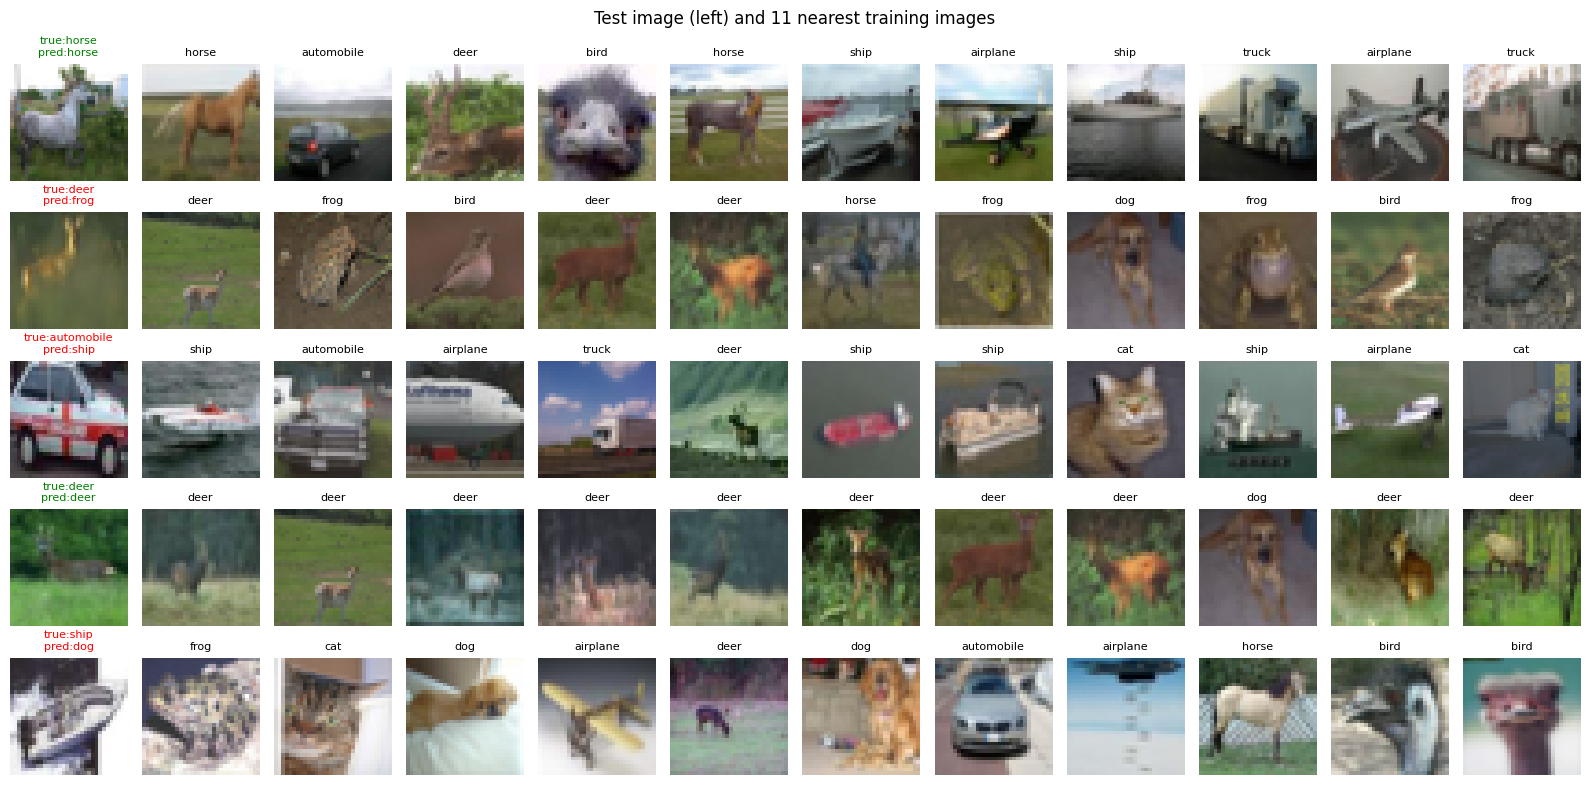

In [ ]:
knn_best = KNN(best_metric).fit(X_tr, y_tr)
show = rng.choice(len(X_te), 5, replace=False)
order = knn_best.neighbor_order(X_te[show], best_k)
pred = knn_best.predict(X_te[show], k=best_k)

to_img = lambda x: x.reshape(3, 32, 32).transpose(1, 2, 0)

fig, axes = plt.subplots(5, best_k + 1, figsize=(16, 8))
for r, i in enumerate(show):
    axes[r, 0].imshow(to_img(X_te[i]))
    axes[r, 0].set_title(f'true:{CLASSES[y_te[i]]}\npred:{CLASSES[pred[r]]}', fontsize=8,
                         color='green' if pred[r] == y_te[i] else 'red')
    for c, j in enumerate(order[r], start=1):
        axes[r, c].imshow(to_img(X_tr[j]))
        axes[r, c].set_title(CLASSES[y_tr[j]], fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle(f'Test image (left) and {best_k} nearest training images')
plt.tight_layout()
plt.show()

## 실험 결과 비교 및 설명

학습 데이터 5,000장(클래스당 500장)으로 5-fold 교차검증을 한 뒤, 테스트 데이터 1,000장(클래스당 100장)으로 최종 평가했다. 거리 방식 3가지(L1, L2, 코사인)와 k 값 10가지(1~50)를 비교했다.

### 거리 측정 방법 비교

- 교차검증 기준 성능은 L1 > 코사인 > L2 순이었고, 최적 조합은 L1 거리, k=11이었다.
- L2가 세 방식 중 가장 낮았다. L2는 픽셀 차이를 제곱하기 때문에 배경처럼 일부 영역이 크게 다르면 거리가 크게 벌어진다. L1은 차이를 그대로 더해서 이런 큰 차이에 덜 민감하다. 코사인 거리는 벡터의 방향만 비교하므로 이미지 전체의 밝기 차이를 무시한다. 그래서 L2보다 높은 성능을 보였다.

### k 값에 따른 변화
- 세 거리 방식 모두 k=1에서 성능이 낮았다. k=1은 가장 가까운 이미지 한 장만 보고 판단해서 잡음에 민감하기 때문이다.
- k를 5~11 정도로 키우면 여러 이웃의 다수결로 잡음이 상쇄되어 성능이 올라갔다.
- k=50에서는 다시 떨어졌다. 거리가 먼, 관련 없는 이미지까지 투표에 참여했기 때문이다.
- L1의 경우 k=3~20 구간의 정확도가 0.305 정도로 거의 같아서, 이 범위에서는 k를 어떻게 골라도 큰 차이가 없었다.

### 평가 지표 비교
- 정밀도는 k가 커질수록 계속 올라갔지만(L1: k=1에서 0.3220, k=30에서 0.4207), 재현율과 F1은 오히려 떨어졌다. k가 커지면 예측이 일부 클래스로 몰리고, 거의 예측되지 않는 클래스는 예측한 것만큼은 맞는 상태가 되어 정밀도가 높아 보이기 때문이다.
- 그래서 정밀도만 보면 큰 k가 좋아 보이지만, 정밀도와 재현율을 함께 반영하는 F1은 k=5(L1 0.2970)에서 가장 높았다. 한 가지 지표만 보면 잘못된 결론을 낼 수 있다.

### 예측 예시와 KNN의 한계
- 최종 정확도는 약 30%로, 무작위 추측(10%)보다는 3배 높지만 실제로 쓰기에는 낮다.
- 예측 예시를 보면, 정답을 맞힌 사슴 이미지의 이웃들은 대부분 초록 풀밭 배경이었다. 반면 빨간 자동차는 빨간 물체와 회색 배경이 비슷한 배 이미지들을 이웃으로 찾아 ship으로 잘못 예측했다.
- 즉, 픽셀 거리는 무엇이 찍혔는지보다 색과 배경이 얼마나 비슷한지를 측정한다. 이것이 원본 픽셀을 쓰는 KNN의 근본적인 한계다.
- 또한 KNN은 예측할 때마다 모든 학습 데이터와 거리를 계산해야 한다. 이번 실험에서도 행렬곱을 쓸 수 없는 L1은 교차검증에 약 227초가 걸린 반면, L2와 코사인은 약 3초가 걸렸다. 데이터가 많아질수록 이 비용은 더 커진다.
- 이런 한계 때문에 학습한 가중치만 저장하는 선형 분류기(f(x) = Wx + b)나, 이미지의 특징을 직접 학습하는 CNN이 필요하다.